# Analysis of prostate trial data

In [1]:
import pandas as pd
import numpy as np
import scipy
import seaborn as sns
import sys
import scipy.stats as stats
from matplotlib.patches import Rectangle

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
%matplotlib inline
import matplotlib as mpl
mpl.rcParams['figure.dpi']= 300
plt.rcParams.update({
    'axes.titlesize': 26,     # Title
    'axes.labelsize': 24,     # X and Y labels
    'xtick.labelsize': 16,    # X tick labels
    'ytick.labelsize': 16,    # Y tick labels
    'legend.fontsize': 14,     # Legend
    'xtick.major.pad':3,
    'ytick.major.pad':3
})

%config Completer.use_jedi = True
from lifelines.utils import concordance_index

sys.path.append("./local/")
import analysisFuns as aFuns
import initialize as initialize

done: set up models
done import aFuns


## load/get data

In [2]:
dataDfName = "./data/MCC 19367_C1.xlsx"

patientIdDic = {2:'102', 3:'103', 4:'104', 5:'105',# 
               6:'106',7:'107',8:'108',9:'109',10:'110',
               11:'111',12:'112',13:'113',14:'114',15:'115',
               16:'116',17:'117'} 
patientIds=[2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17]
start_pids = patientIds[:]
txCols = ["ADT","Abi","ARSI"]

#from data sheet
statusELN=[0,2,2,2,1,1,2,0,2,0,2,2,2,2,1,2]#0=early, 1=late, 2=nonprogresor
dataProg=pd.read_excel(dataDfName,sheet_name='Table', header=0)
TTP=dataProg['TTP (days)']
statusPN=np.where(np.isnan(TTP),0,1)
TTP=TTP.fillna(0)
TTRP=dataProg['TTRP (days)']
statusRP=np.where(np.isnan(TTRP),0,1)
TTRP=TTRP.fillna(0)
DOD=dataProg['OS (days)']
statusD=np.where(np.isnan(DOD),0,1)
DOD=DOD.fillna(0)
GS=dataProg['Gleason score']
metsTemp=dataProg['# mets baseline (bone,LN,other)']
BMs=metsTemp.str.get(0)
BMs=BMs.astype(int)
LNs=metsTemp.str.get(2)
LNs=LNs.astype(int)
others=metsTemp.str.get(4)
others=others.astype(int)
TMs=BMs+LNs+others
risk=dataProg['risk status']
risk=np.where(risk=='high',1,np.where(risk=='low',0,np.nan))
prevTxs=dataProg['Previous txs']
dNM1=np.where(prevTxs=='de novo',1,0)
Abi=dataProg['Abi given']
Abi=np.where(Abi=='Y',1,0)

dataVals=pd.DataFrame()
dataVals['progPSA']=TTP
dataVals['progRP']=TTRP
dataVals['progOS']=DOD
dataVals['ELNstatus']=statusELN
dataVals['PNstatus']=statusPN
dataVals['Dstatus']=statusD
dataVals['RPstatus']=statusRP
dataVals['TTP']=TTP
dataVals['DOD']=DOD
dataVals['Abi']=Abi
dataVals['GS']=GS
dataVals['BMs']=BMs
dataVals['LNs']=LNs
dataVals['TMs']=TMs
dataVals['risk']=risk
dataVals['dNM1']=dNM1

dataTable=pd.read_excel(dataDfName,sheet_name='Table', header=0)
dataVals['Age']=dataTable['Age']
dataVals['BMI']=dataTable['BMI baseline']


## find best fit doubling times

/var/folders/y3/nxptvxqn0z12b_ylwgl4x68h000wg8/T/ipykernel_12492/1567358468.py:94: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataD2['Days2']=dataD2['Days']-dataD2['Days'].iloc[0]


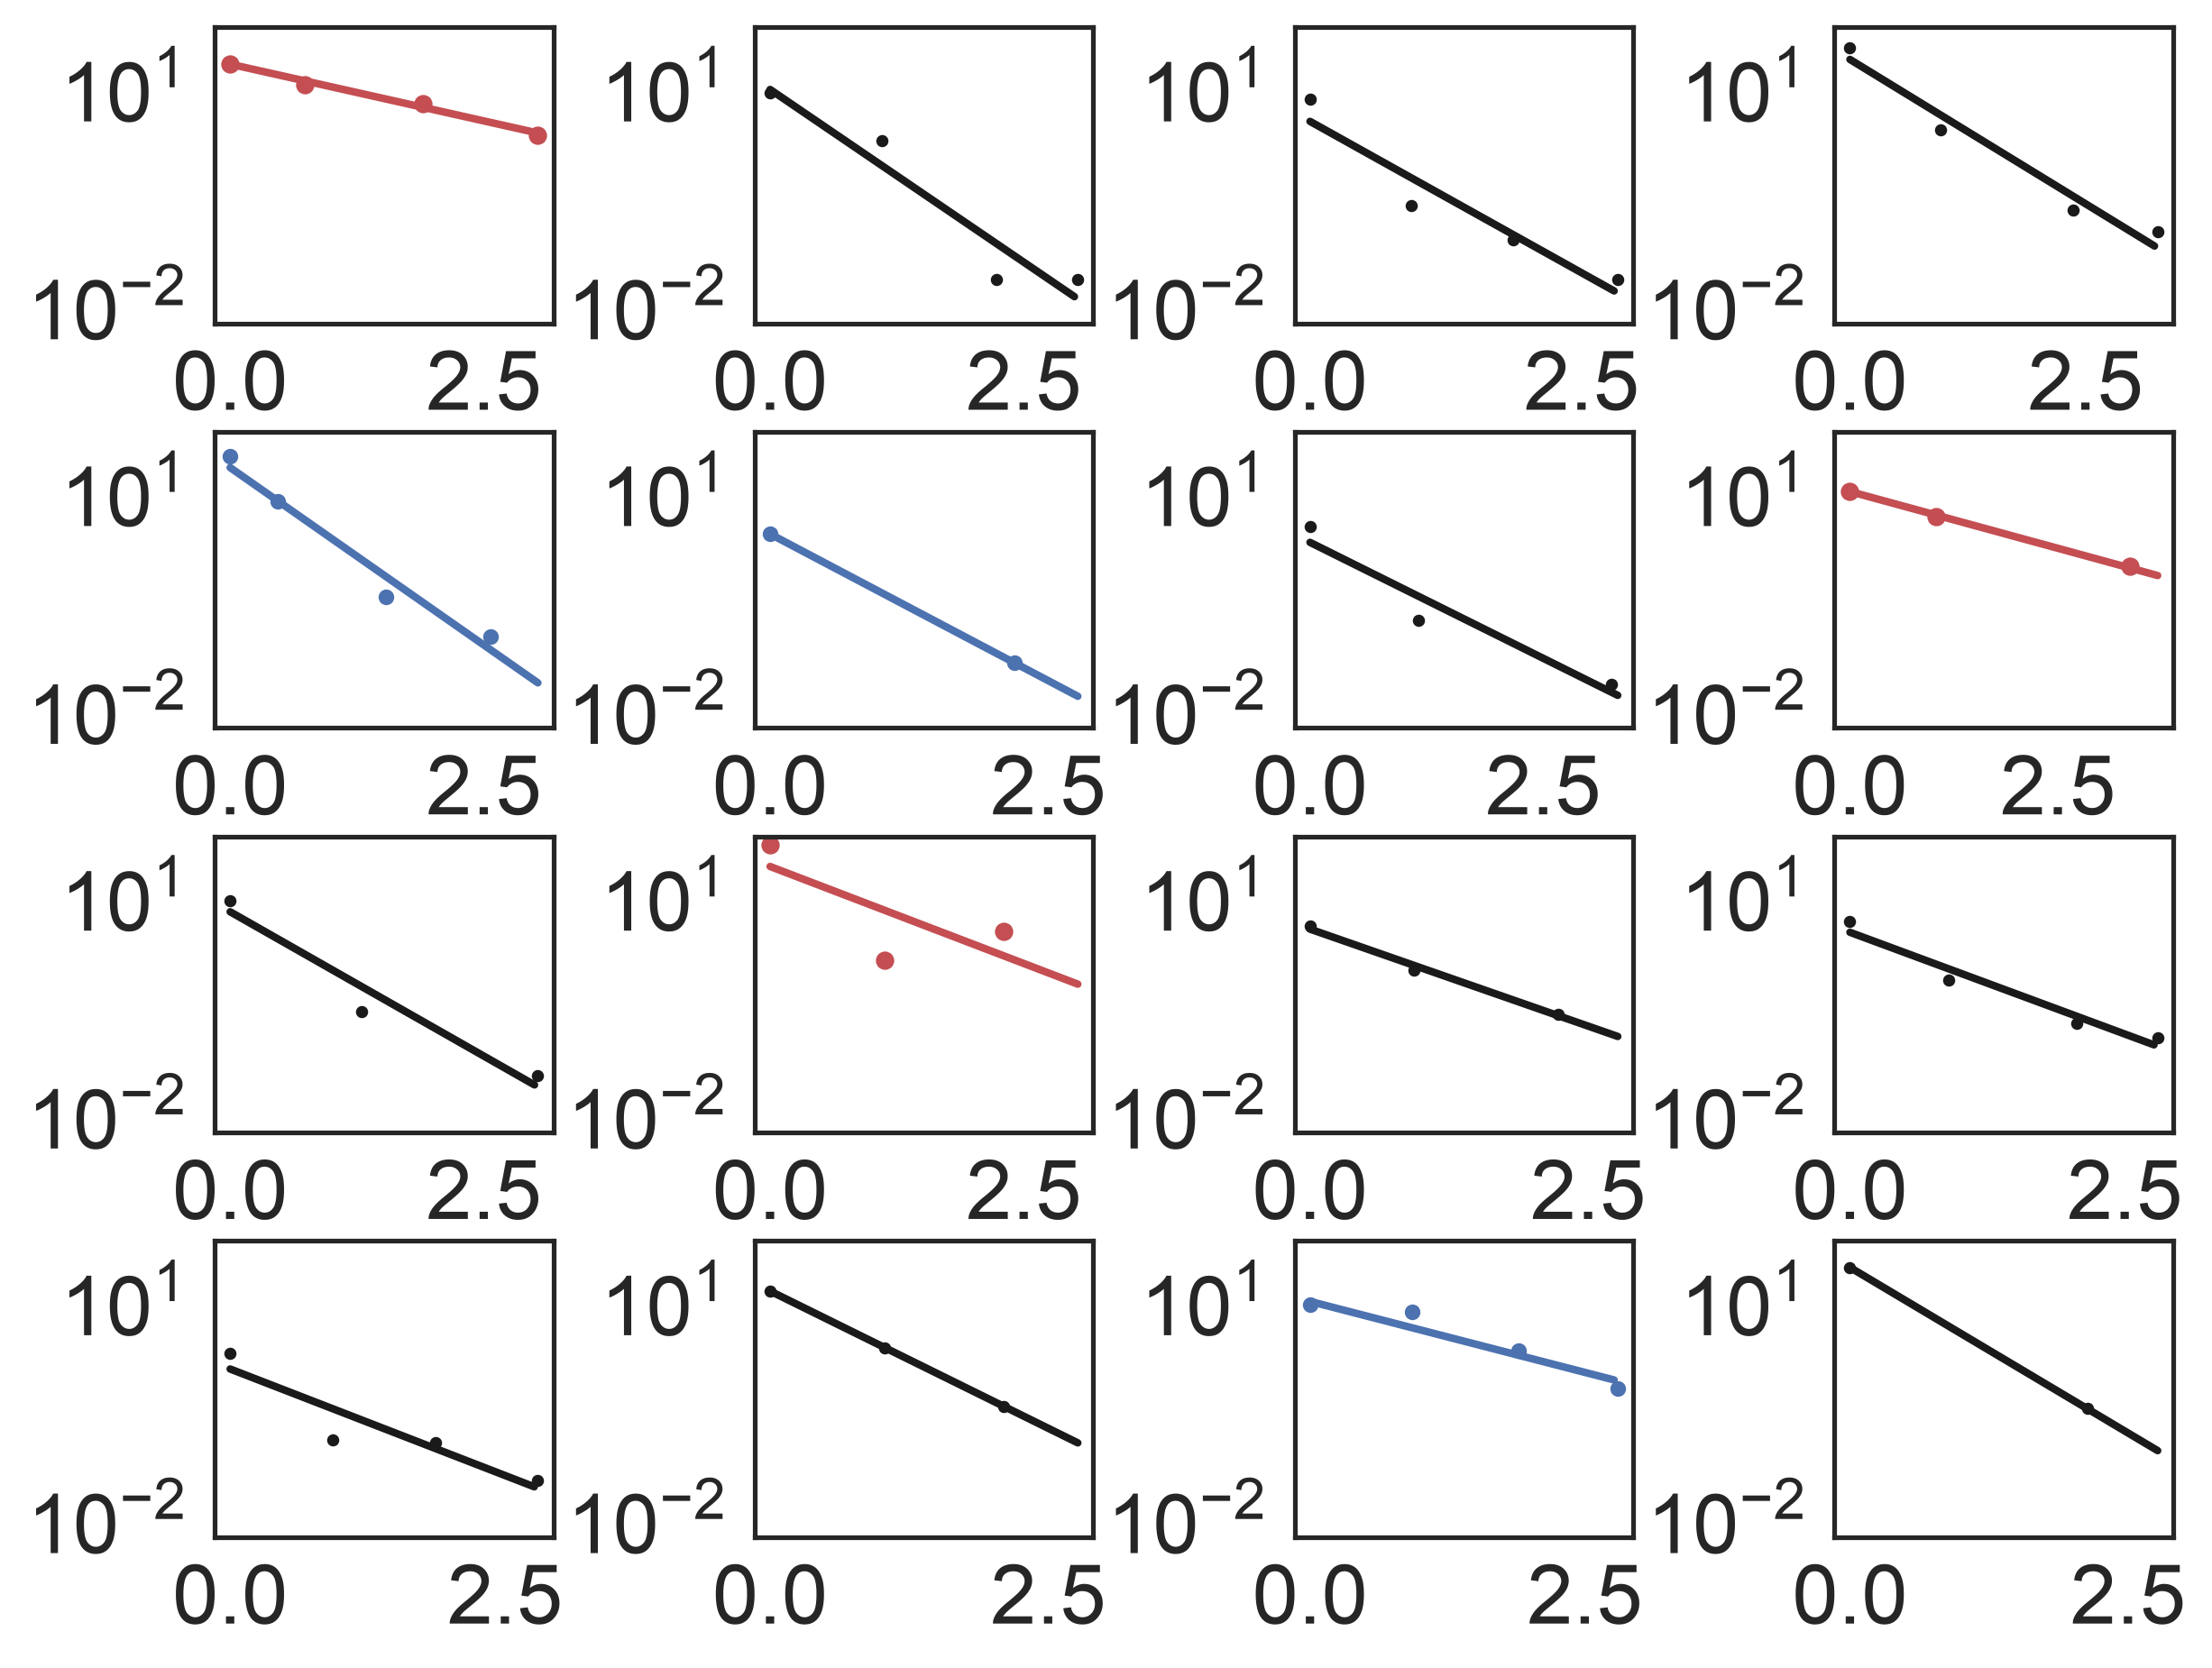

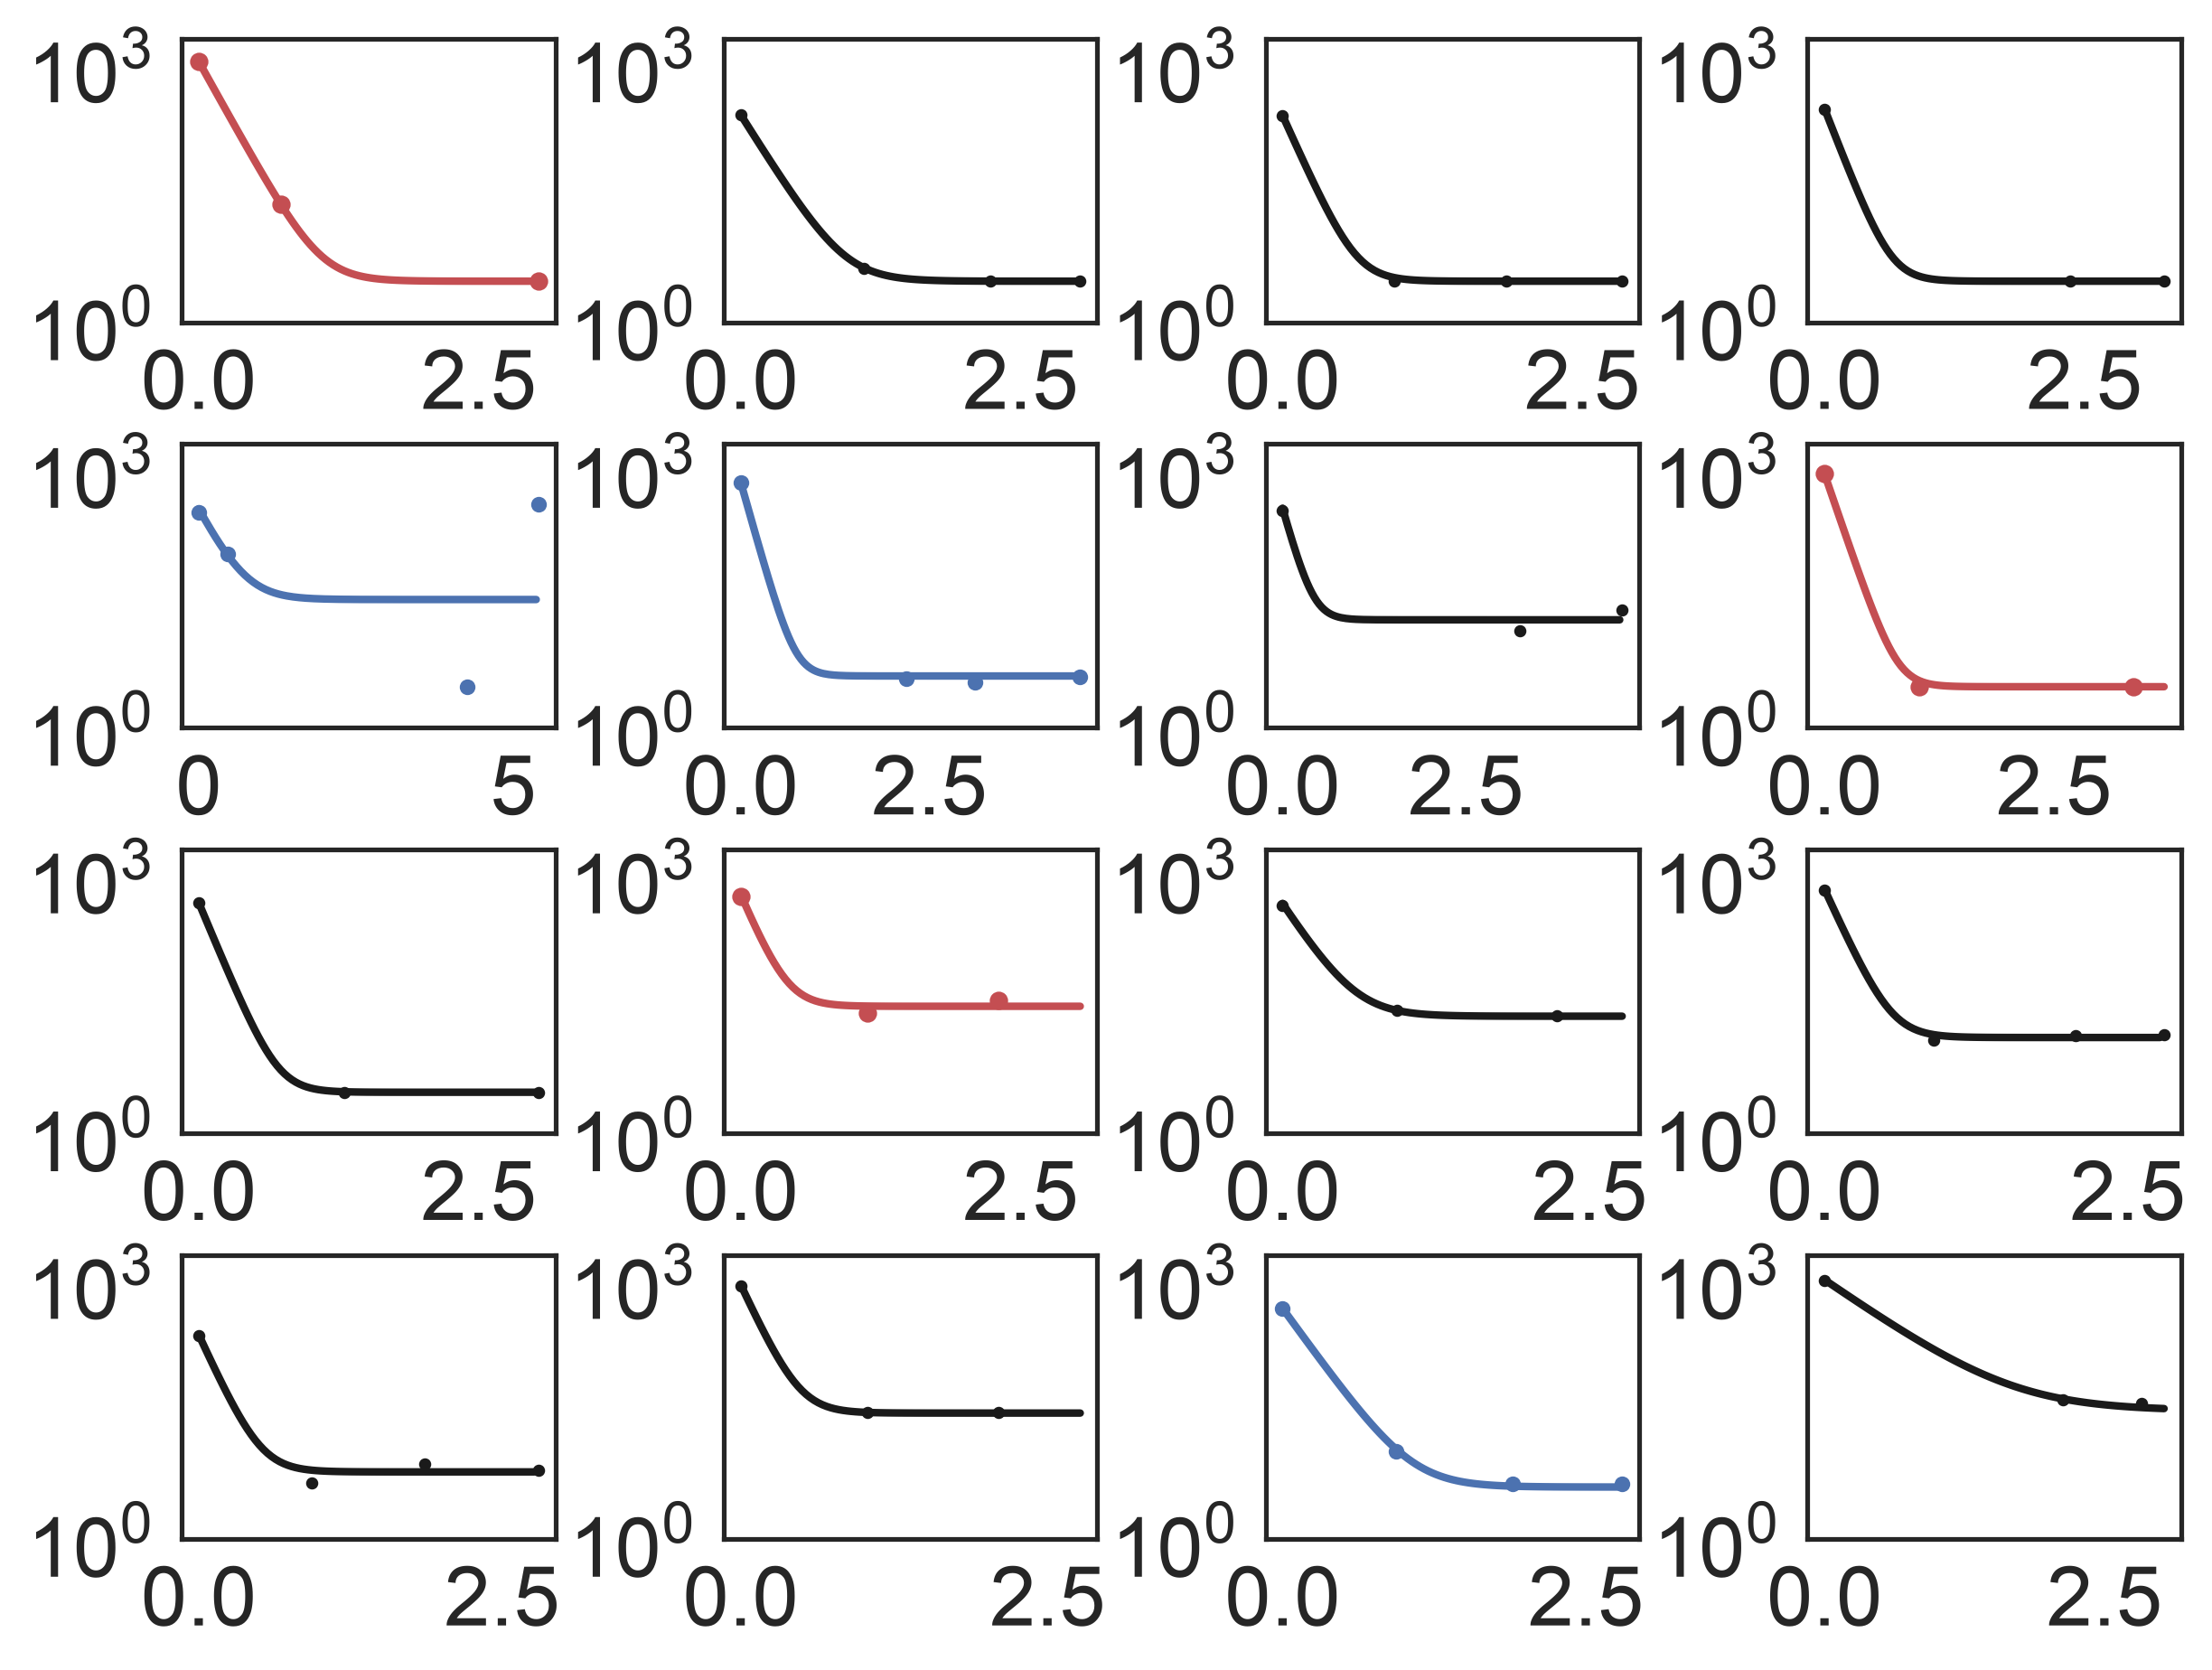

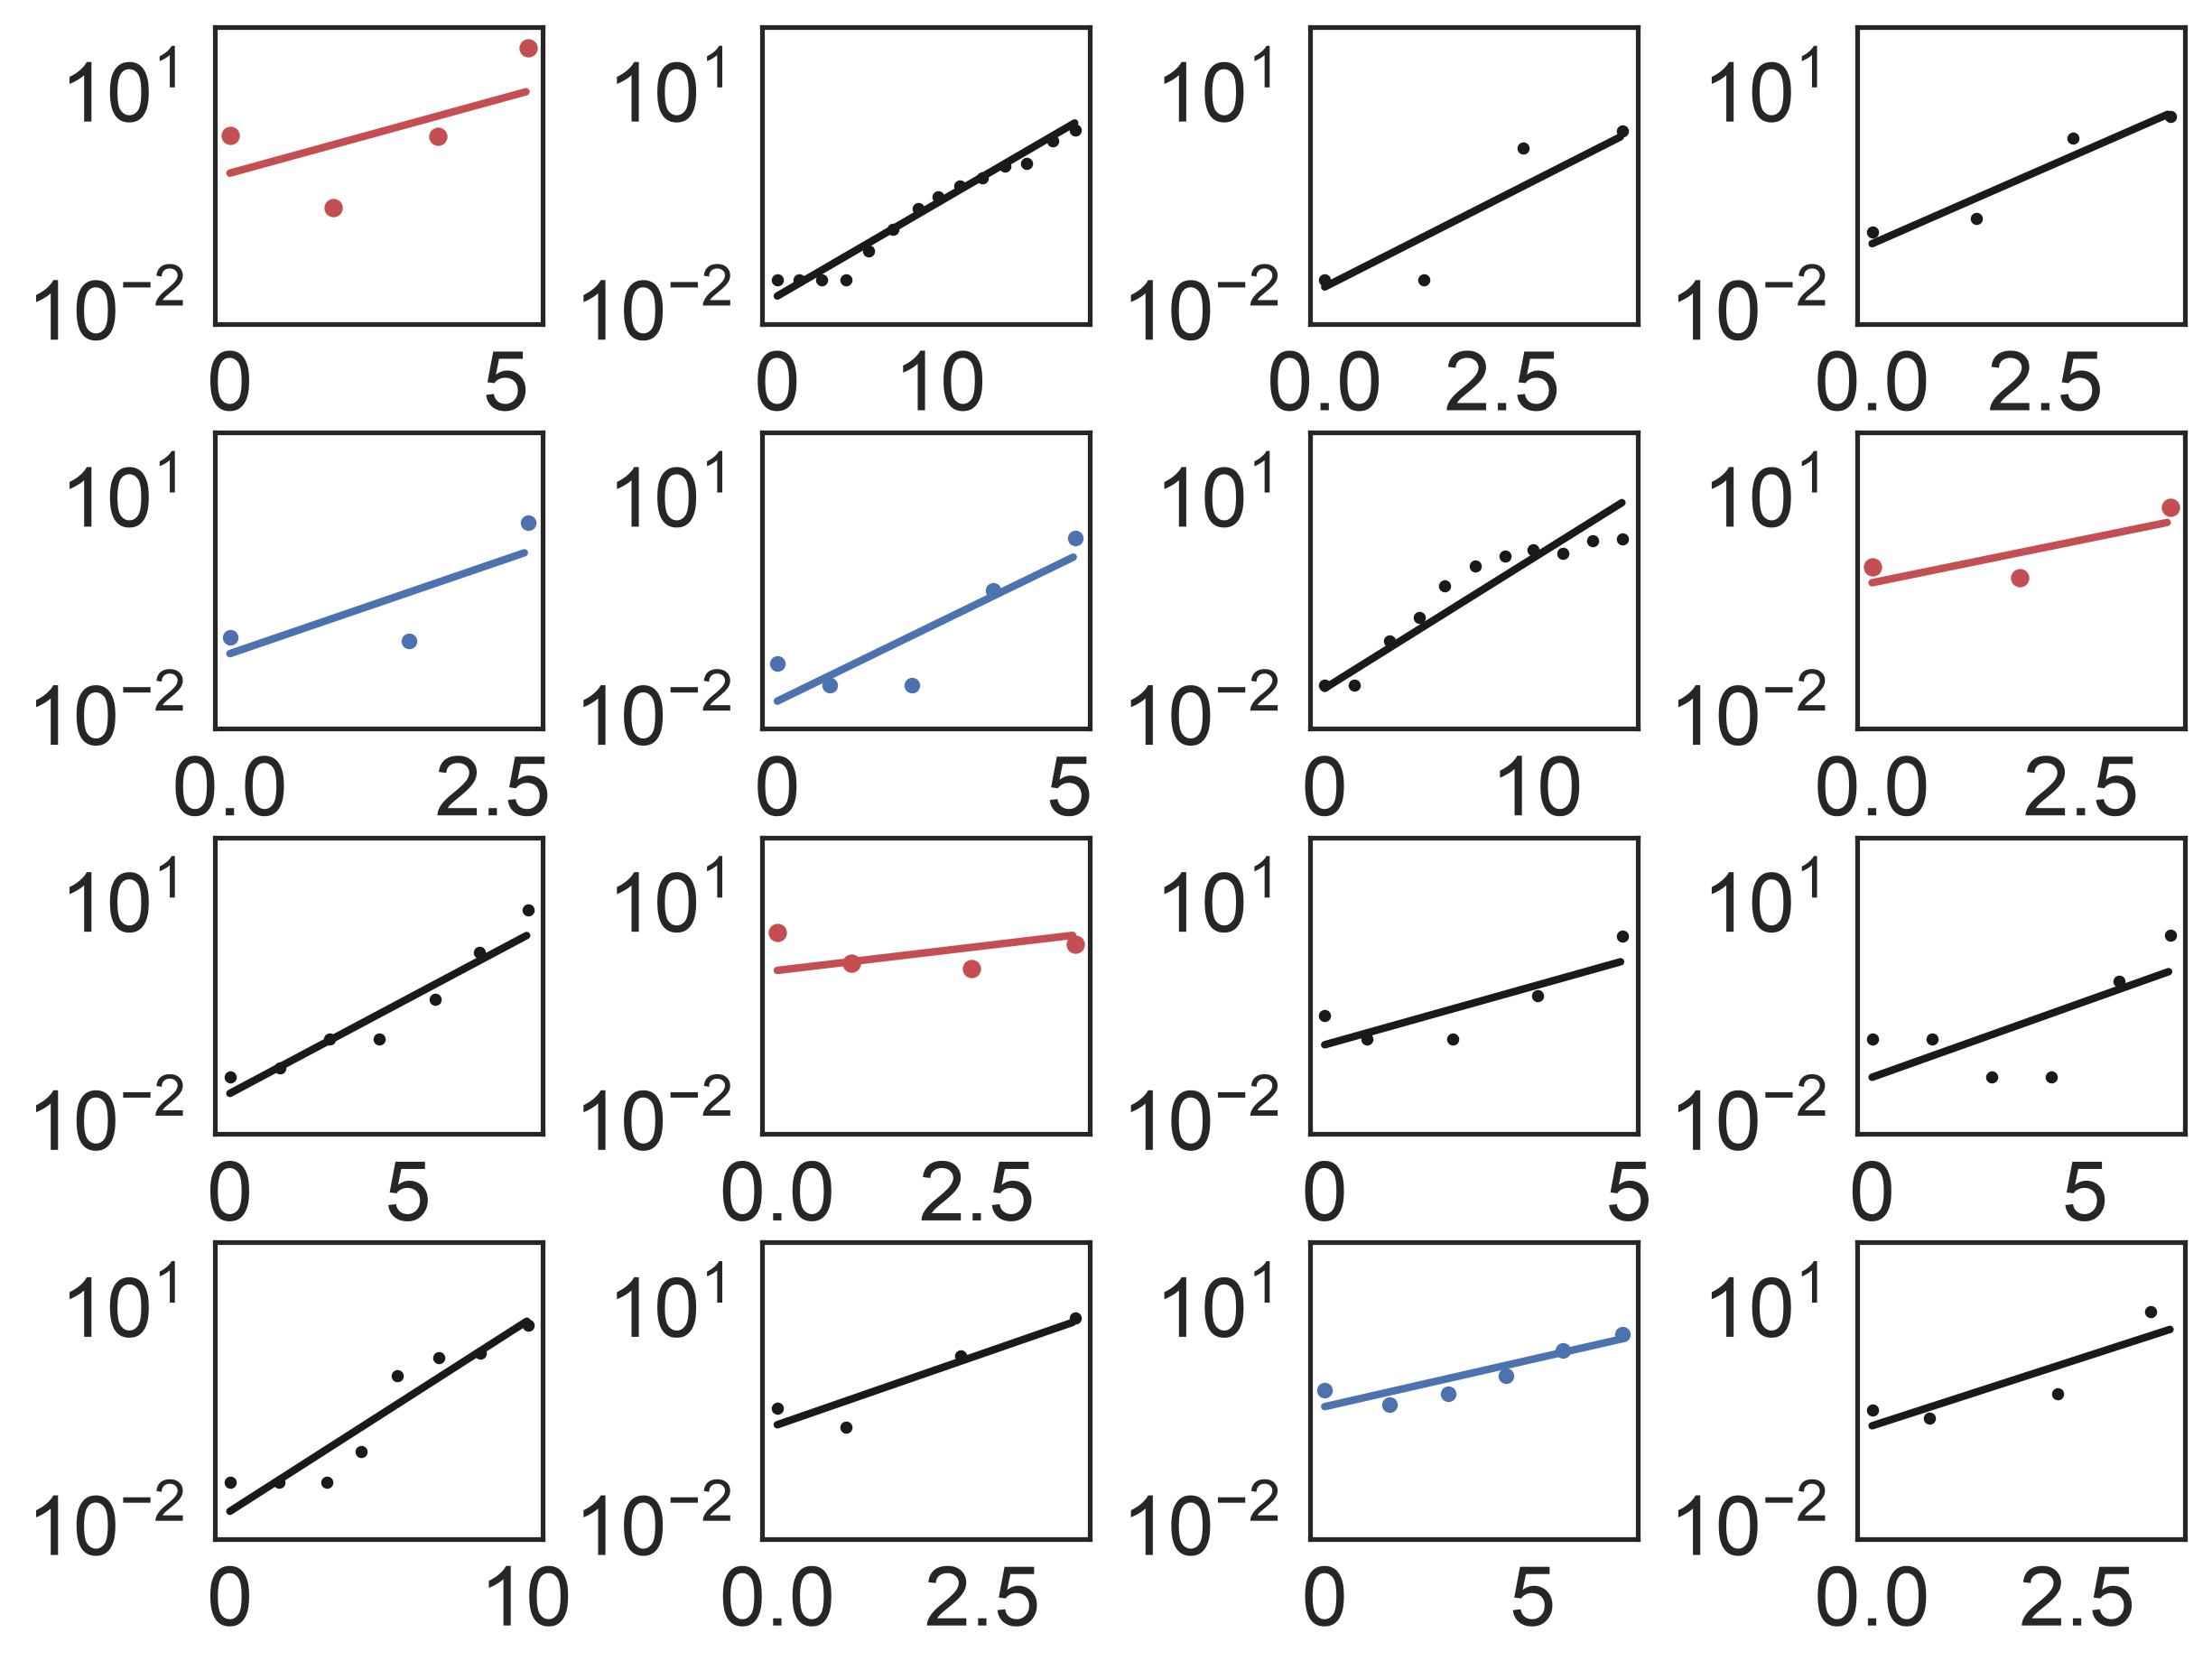

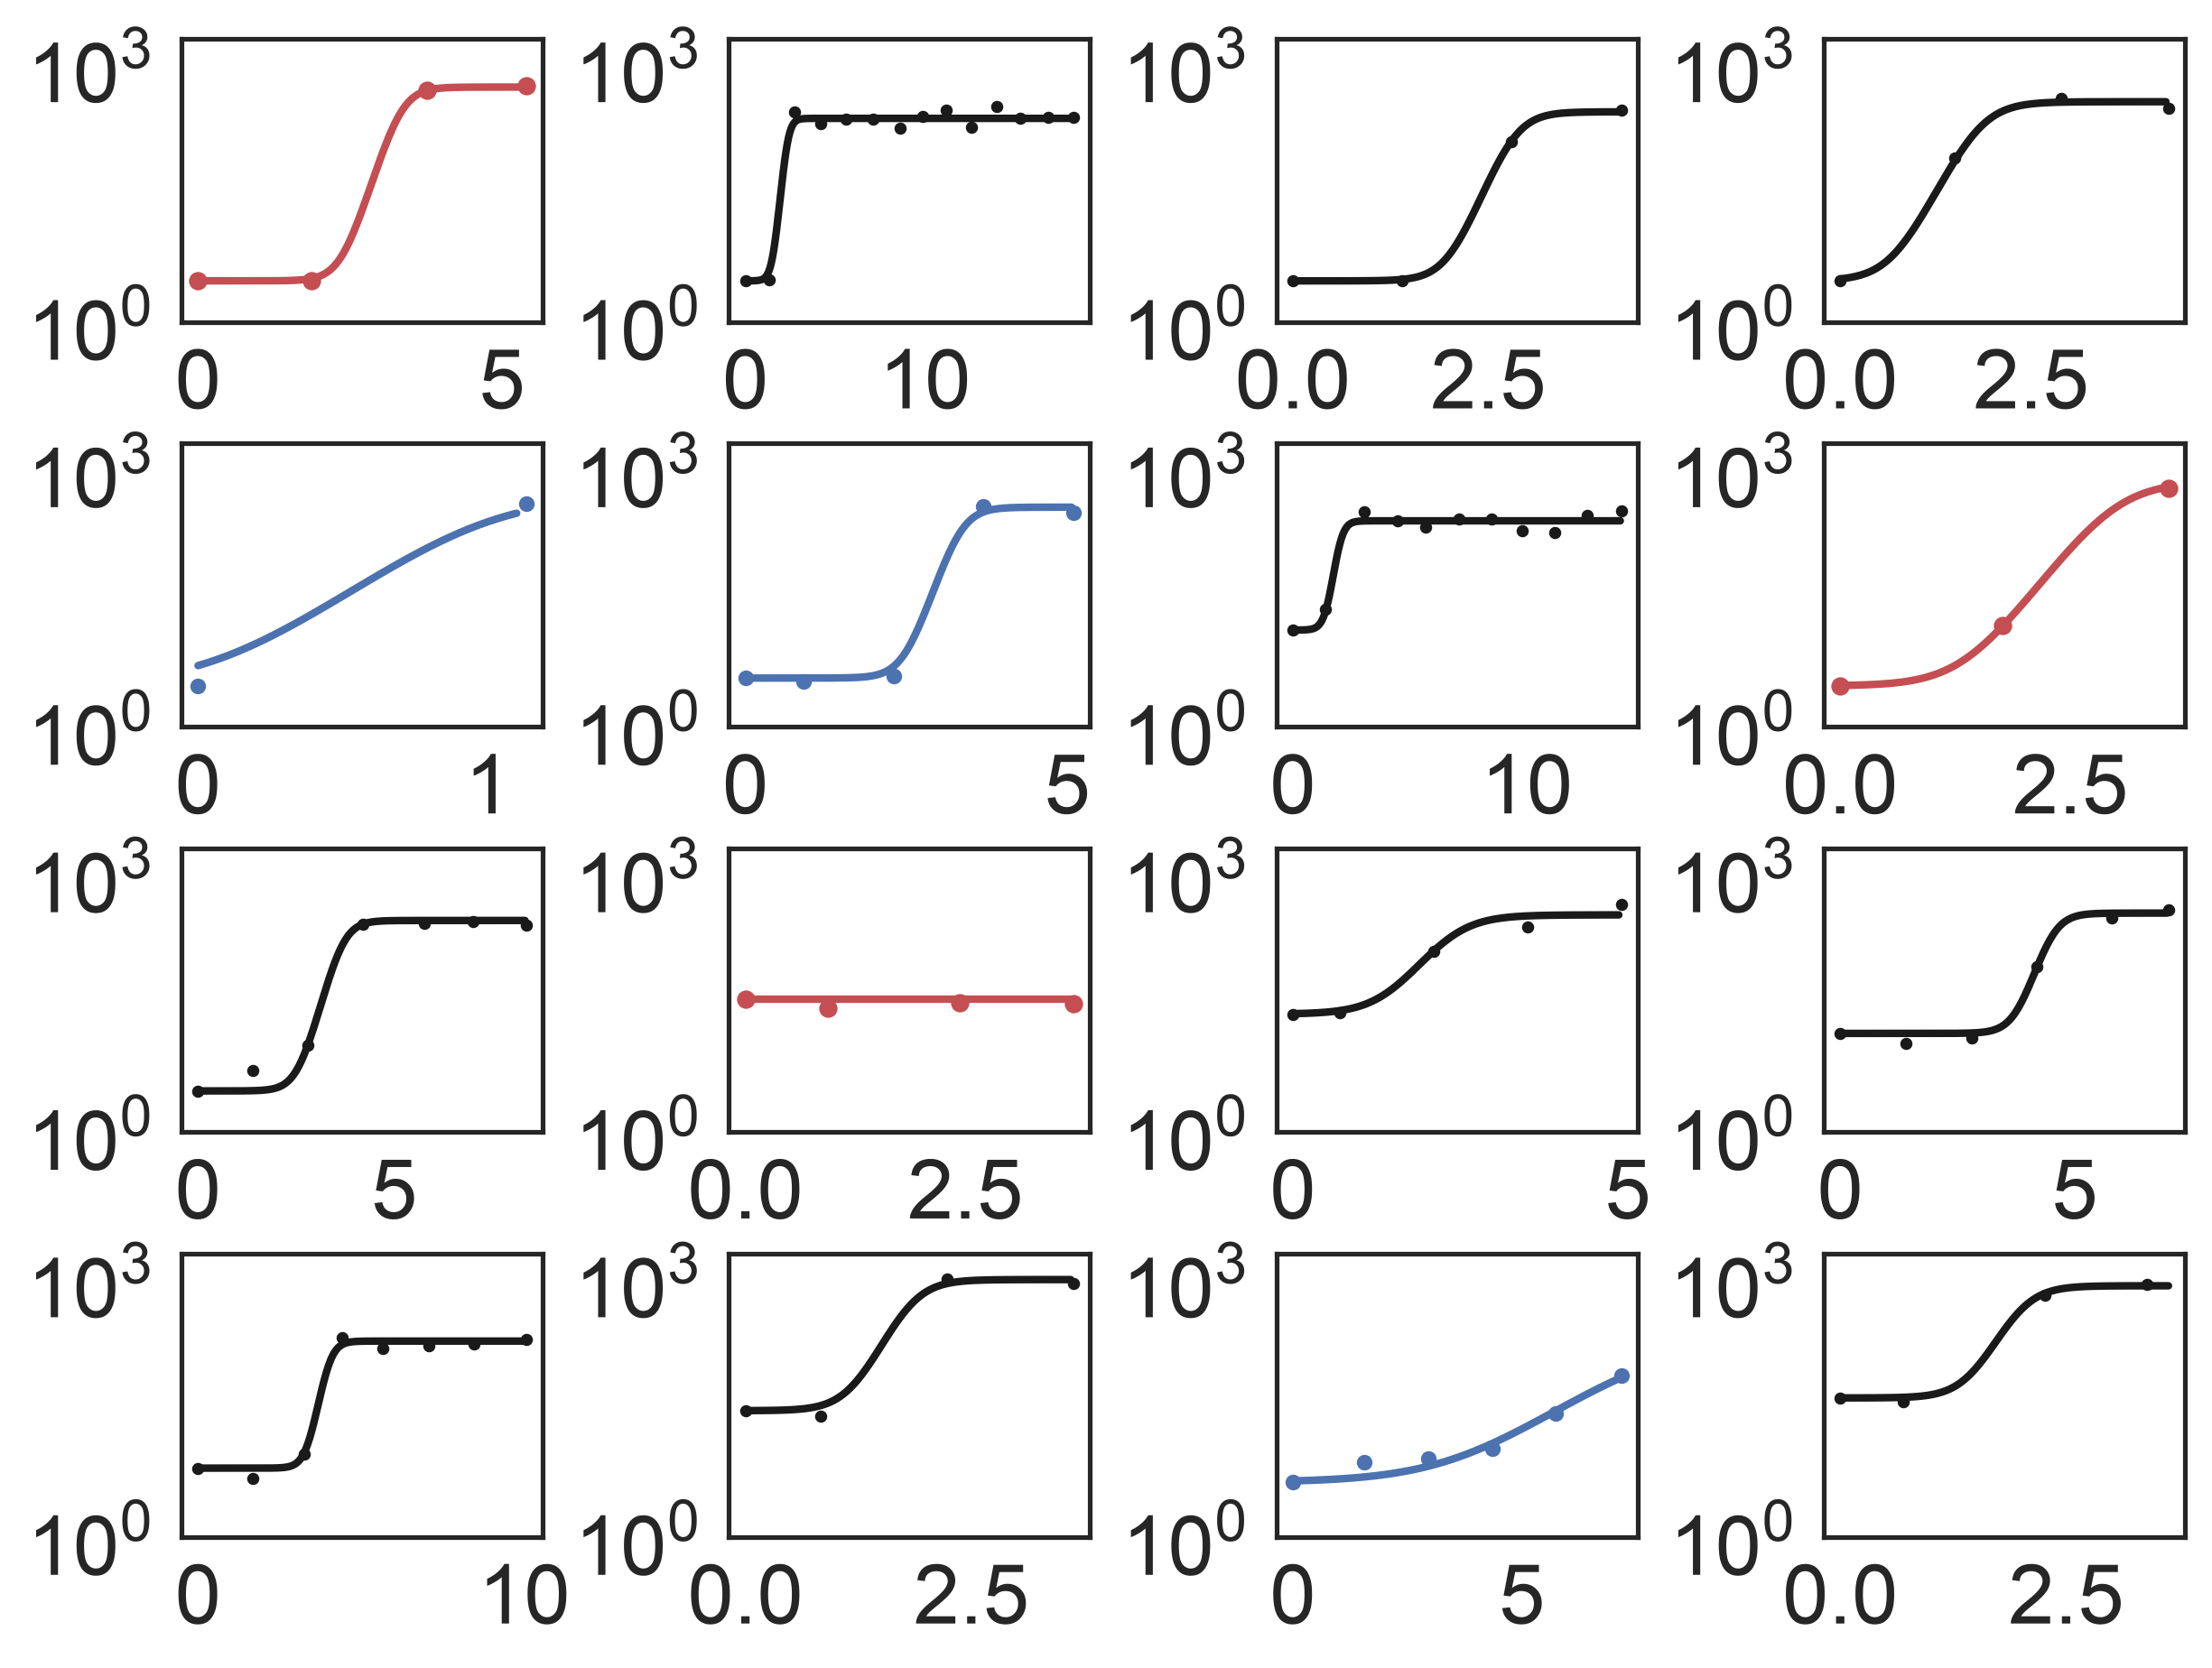

In [3]:
onVals=[True,False]
plotVarVals=['PSA','Testosterone']

import math
minTR=np.arange(2,32,1)
dRTR=np.arange(.05,.25,.01)
minTfit=[]
dRTfit=[]

maxPR=np.arange(.5,1.2,.1)
dRPR=np.arange(.02,.09,.001)
maxPfit=[]
dRPfit=[]

minPR=np.arange(.3,1,.1)
gRPR=np.arange(.01,.04,.002)
minPfit=[]
gRPfit=[]

maxTR=np.arange(.3,1.6,.1)
gRTR=np.arange(.02,.19,.01)
tdelayR=np.arange(30,300,5)
maxTfit=[]
gRTfit=[]
tdelayfit=[]

patientOrder=[2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17]
col=['r','k','k','k','b','b','k','r','k','r','k','k','k','k','b','k']
lw=[3,1,1,1,2,2,1,3,1,3,1,1,1,1,2,1]
siz=[15,5,5,5,10,10,5,15,5,15,5,5,5,5,10,5]

def evalModel1(a,b,t2):
    if(plotVar=='PSA' and on):
        return [a*dataD2[plotVar].iloc[0]*math.exp(-b*t) for t in t2]
    elif(plotVar=='PSA' and (not on)):
        return [a*dataD2[plotVar].iloc[0]*math.exp(b*t) for t in t2]
    else:
        return [a+dataD2[plotVar].iloc[0]*math.exp(-b*t) for t in t2]

def sampleParams(p1,p2,t2):
    errMin=1000000000
    fit1=[]
    fit2=[]
    for a in p1:
        for b in p2:
            modFit=evalModel1(a,b,t2)
            sumEr=0
            dd2=dataD2[plotVar]
            for ti,tt in enumerate(dd2):
                #if(not np.isnan(tt)):sumEr=sumEr+(tt-modFit[ti])*(tt-modFit[ti])
                if(not np.isnan(tt)):sumEr=sumEr+(np.log(tt)-np.log(modFit[ti]))*(np.log(tt)-np.log(modFit[ti]))
            if(sumEr<errMin):
                bestfit[0]=a
                bestfit[1]=b
                errMin=sumEr
    fit1.append(bestfit[0])
    fit2.append(bestfit[1])
    return [fit1,fit2]

parfits=pd.DataFrame()
for on in onVals:
    for plotVar in plotVarVals:
        fig, ax = plt.subplots(4, 4, figsize=(8,6))
        aveP=[]
        xx=0
        yy=0
        for pi,pat in enumerate(patientOrder):
            patId = patientIdDic[pat]
            dataD = initialize.loadData(dataDfName,patId,txCols)
            T0=dataD['Testosterone'].iloc[0]
            indSwitch=np.where(dataD['DrugIndex']==0)[0][0]
            dataD2=dataD.copy()
            if(on):
                dataD2=dataD2[0:indSwitch]
                lastNan=np.isnan(dataD2['Testosterone'].iloc[-1])
                if((len(dataD2[~np.isnan(dataD2['Testosterone'])])<3) and (not plotVar=='PSA')): 
                    dataD2=dataD.copy()
                    dataD2=dataD2[0:indSwitch+2]
            else:
                tmpD2=dataD2[indSwitch-1:]
                if(plotVar=='PSA'):
                    if(np.isnan(tmpD2['PSA'].iloc[0])):
                        tmp=dataD2['PSA'][indSwitch-2]
                        if(np.isnan(tmp)):dataD2=dataD2[indSwitch-3:len(dataD2['PSA'])]
                        else:dataD2=dataD2[indSwitch-2:len(dataD2['PSA'])]
                    else:dataD2=tmpD2
                else:
                    if(np.isnan(tmpD2['Testosterone'].iloc[0])):
                        dataD2=tmpD2
                        newRow=dataD.iloc[dataD[:indSwitch]['Testosterone'].last_valid_index()]
                        if(newRow['Testosterone']<50):dataD2=pd.concat([pd.DataFrame(newRow).T,tmpD2], ignore_index=True)
                        else:dataD2=tmpD2.loc[tmpD2['Testosterone'].first_valid_index():]
                    else:dataD2=tmpD2
            dataD2['Days2']=dataD2['Days']-dataD2['Days'].iloc[0]
            inds=np.where(~np.isnan(dataD2[plotVar]))[0]
            t1=range(0,round(max(dataD2['Days2'])))

            if((not plotVar=='PSA') and (not on)): bestfit=[0,0,0]
            else: bestfit=[0,0]
            t2=dataD2['Days2']
            if((not plotVar=='PSA') and (not on)):
                errMin=1000000000
                for a in maxTR:
                    for b in gRTR:
                        for c in tdelayR:
                            modFit = [dataD2['Testosterone'].iloc[0] + a*T0/(1+math.exp(-b*(t-c))) for t in t2] 
                            sumEr=0
                            for ti,tt in enumerate(dataD2['Testosterone']):
                                if(not np.isnan(tt)):
                                    sumEr=sumEr+(np.log(tt)-np.log(modFit[ti]))*(np.log(tt)-np.log(modFit[ti]))
                            if(sumEr<errMin):
                                bestfit[0]=a
                                bestfit[1]=b
                                bestfit[2]=c
                                errMin=sumEr
                maxTfit.append(bestfit[0])
                gRTfit.append(bestfit[1])
                tdelayfit.append(bestfit[2])
            else:
                if(on and plotVar=='PSA'):
                    [f1,f2]=sampleParams(maxPR,dRPR,t2)
                    maxPfit.append(f1[0])
                    dRPfit.append(f2[0])
                elif(on and (not plotVar=='PSA')):
                    [f1,f2]=sampleParams(minTR,dRTR,t2)
                    minTfit.append(f1[0])
                    dRTfit.append(f2[0])
                else:
                    [f1,f2]=sampleParams(minPR,gRPR,t2)
                    minPfit.append(f1[0])
                    gRPfit.append(f2[0])
            p1=[]
            if(on):
                if(plotVar=='PSA'):p1 = [bestfit[0]*dataD2[plotVar].iloc[0]*math.exp(-bestfit[1]*t) for t in t1] 
                else:p1 = [bestfit[0] + dataD2[plotVar].iloc[0]*math.exp(-bestfit[1]*t) for t in t1]  
            else:
                if(plotVar=='PSA'):p1 = [bestfit[0]*dataD2[plotVar].iloc[inds[0]]*math.exp(bestfit[1]*t) for t in t1] 
                else:p1 = [dataD2[plotVar].iloc[0]+bestfit[0]*T0/(1+math.exp(-bestfit[1]*(t-bestfit[2]))) for t in t1] 
            if(plotVar=='PSA'):ax[yy][xx].set_ylim([5E-3,60])
            else:ax[yy][xx].set_ylim([1,2000])

            t2=[x/30 for x in t1]
            ax[yy][xx].plot(t2,p1,c=col[pi],linewidth=2)
            aveP.append(np.nanmean(p1))
            ax[yy][xx].scatter(dataD2['Days2'].iloc[inds]/30,dataD2[plotVar].iloc[inds],c=col[pi],s=siz[pi])
            ax[xx][yy].set_yscale('log')
            #update index for next
            xx=xx+1
            if(xx>3):
                xx=0
                yy=yy+1
  
        plt.tight_layout(pad=0.1)

parfits['maxTfit']=maxTfit
parfits['gRTfit']=gRTfit
parfits['tdelayfit']=tdelayfit 
parfits['maxPfit']=maxPfit
parfits['dRPfit']=dRPfit  
parfits['minTfit']=minTfit
parfits['dRTfit']=dRTfit 
parfits['minPfit']=minPfit
parfits['gRPfit']=gRPfit  

## add best fit model values to data frame

In [4]:
# get model fit vals
rS=[]
X0=[]
for pat in patientIds:
    pId=patientIdDic[pat]
    fileName="./output/modPCaSX/parWinsmodPCaSX"+str(pId)+".xlsx"
    pData=pd.read_excel(fileName,header=0)
    for col in pData.columns:
        if(col=='r_S'):rS.append(pData[col].iloc[0])
        elif(col=='X0'):X0.append(pData[col].iloc[0])

modVals=pd.DataFrame()
modVals['rS']=rS#rD
modVals['X0']=X0#xS

## calculate metrics for 1st cycle

In [5]:
allDf=pd.DataFrame()
for pi,pat in enumerate(patientIdDic):
    dataDf=initialize.loadData(dataDfName,patientIdDic[pat],txCols)
    pData = aFuns.calculateMetrics(pat,pi,dataDf,dataVals,modVals,parfits)
    frames0=[allDf, pData]
    allDf=pd.concat(frames0,ignore_index=True)

## plot individual patients

4
4
5
5
1
0
0


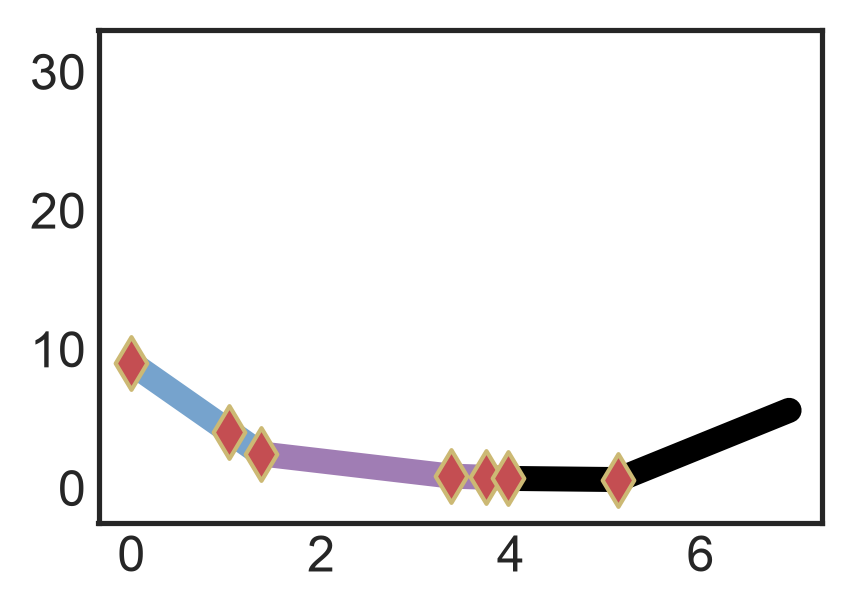

In [6]:
########################################################
# Options
# choose the plot type as PSA, testosterone, or P/T
########################################################
plotType='PSA'#Testosterone = 'Testo'; PSA = 'PSA','Testo'; P/T = 'PT'
#patientIdDic0 = {1:'105'}
patientIdDic0 = {2:'109'}
#patientIdDic0 = {3:'111'}


import math
from matplotlib.patches import Rectangle
import itertools as itools
fig, ax = plt.subplots(1, 1, figsize=(3,2.2),dpi=300)

colors={1:'k',2:'r'}
palette = {'0': "#000000",'1':"#CD7A6E",'2':"#CD7A6E",'4': "#76A3CD",'5': "#A07DB4",'6': "#A07DB4"}

for patientId in patientIdDic0.keys():
    dataDf = initialize.loadData(dataDfName,patientIdDic0[patientId],txCols)
    psa0=10*(math.log(dataDf['PSA'].iloc[0])+1)

    bstr=[]
    indCol=[]
    for i in range(0,len(dataDf[txCols[0]])):
        tmpARSI=int(np.ceil(dataDf['ARSI'][i]))
        b=str(dataDf[txCols[0]][i])+str(dataDf[txCols[1]][i])+str(tmpARSI)
        bstr.append(int(b,2))

    drugOnTimes=[0]
    drugOffTimes=[]
    indOff=0
    indOn=0
    indOn0=0
    bstr0=bstr
    indsOnAll=[]
    while len(bstr0)>1:
        if(0 in bstr0):
            indOff0=bstr0.index(0)
            indOff=indOff+indOff0+indOn0
            drugOffTimes.append(indOff)
            bstr0=bstr0[indOff0:]
            if(sum(bstr0)>0):
                indOn0=np.nonzero(bstr0)[0][0]
                indOn=indOn0+indOff
                indsOnAll.append(indOn)
                drugOnTimes.append(indOn)
                bstr0=bstr0[indOn0:]
            else:
                break
        else:
            break

    dataDf['PSA']=dataDf['PSA'].interpolate()
    dataDf['Testosterone']=dataDf['Testosterone'].interpolate()

    ##### add line
    if(dataDf['PSA'][0]>10):
        tmax0=10-2
    elif(dataDf['PSA'][0]<=2):
        tmax0=.001
    else:
        tmax0=dataDf['PSA'][0]-2
    days=dataDf['Days']/30

    indF=len(dataDf['Days'])-1
    days=dataDf['Days'][0:indF+1]/30
    testo=dataDf['Testosterone'][0:indF+1]
    psa=dataDf['PSA'][0:indF+1]
    
    if(plotType=='Testo'):
        if(patientIdDic0[patientId]=='105'):
            testo[0]=402.2# - 105
        inds=~np.isnan(testo)
        bstrI=list(itools.compress(bstr, inds))
        daysI=list(itools.compress(days, inds))
        testoI=list(itools.compress(testo, inds))
        for bi,b in enumerate(bstr[0:indF]): 
            if(bi>=len(bstr)):
                days=daysI[bi-2:bi]
                testo=testoI[bi-2:bi]
            else:
                days=daysI[bi:bi+2]
                testo=testoI[bi:bi+2]
            ax.plot(days,testo,c=palette[str(b)],linewidth=6.0,zorder=1)
            ax.scatter(dataDf['Days'][bi]/30,dataDf['Testosterone'][bi],color=colors[patientId],s=80,edgecolors='y',marker='d')
        days=dataDf['Days']/30
    elif(plotType=='PSA'):
        totalT=0
        for bi,b in enumerate(bstr[0:indF]):
            print(b)
            if(bi>=len(bstr)):
                days=dataDf['Days'].loc[bi-1:bi]/30
                psa=dataDf['PSA'].loc[bi-1:bi]
                testo=testoI[bi-2:bi]
            else:
                days=dataDf['Days'].loc[bi:bi+1]/30
                psa=dataDf['PSA'].loc[bi:bi+1]
            ax.plot(days,psa,c=palette[str(b)],linewidth=6.0,zorder=1)
            ax.scatter(dataDf['Days'][bi]/30,dataDf['PSA'][bi],color=colors[patientId],s=80,edgecolors='y',marker='d')
        days=dataDf['Days']/30
    elif(plotType=='PT'):
        if(patientIdDic0[patientId]=='105'):
            testo[0]=402.2# - 105
        inds=~np.isnan(testo)
        bstrI=list(itools.compress(bstr, inds))
        daysI=list(itools.compress(days, inds))
        testoI=list(itools.compress(testo, inds))
        psaI=list(itools.compress(psa,inds))
        for bi,b in enumerate(bstrI[0:indF]):
            if(bi>=len(bstrI)):
                days=daysI[bi-2:bi]
                testo2=testoI[bi-2:bi]
                psa2=psaI[bi-2:bi]
                pt=[0.01*psa2[i]/testo2[i] for i in range(0,len(psa2))]
            else:
                days=daysI[bi:bi+2]
                testo2=testoI[bi:bi+2]
                psa2=psaI[bi:bi+2]
                pt=[0.01*psa2[i]/testo2[i] for i in range(0,len(psa2))]
            ax.plot(days,pt,c=palette[str(b)],linewidth=6.0,zorder=1)
            ax.scatter(dataDf['Days'][bi]/30,0.01*dataDf['PSA'][bi]/dataDf['Testosterone'][bi],color=colors[patientId],s=80,edgecolors='y',marker='d')
        days=dataDf['Days']/30

if(plotType=='PSA'):
    plt.ylim([-2.5,33])
elif(plotType=='Testo'):
    plt.ylim([-30,950])
else:
    plt.ylim([-.001,.016])


ax.tick_params(labelsize=12)
ax.tick_params("y", pad=-3)
ax.tick_params("x", pad=-3)
plt.tight_layout()

## plot PSA and Testosterone dynamics

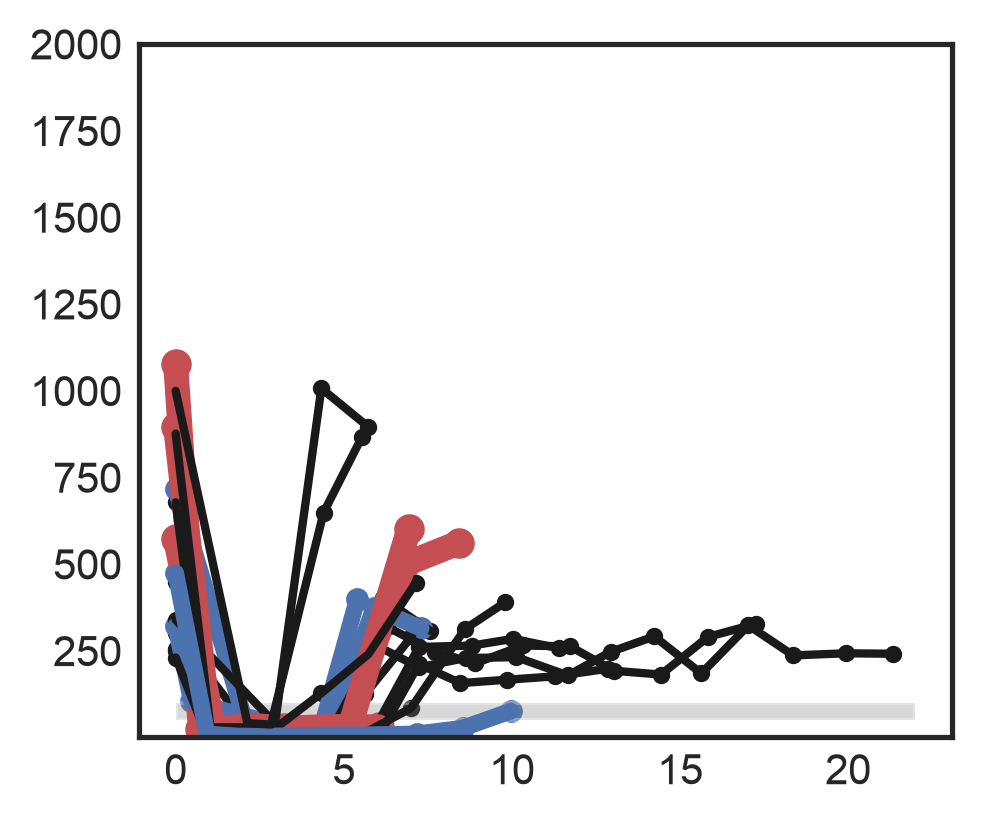

In [7]:
########################################################
# Options:
# choose the plot type as PSA, testosterone
# choose the x-axis scaling as True/False 
# choose the y-axis scaling as Log or Linear
########################################################

PlotType='Testosterone' #'PSA', 'Testosterone', 'PSA/T'
timeScaled=False #True = all patients time scaled over 1st cycle the same; time is in days
logScaled=False #True = log scale

fsize=(3.5,3)
if(timeScaled and logScaled):fsize=(8,3.8)#fsize=(8,4.5) #longer for P&T, shorter for P/T
fig, ax = plt.subplots(1, 1, figsize=fsize)#figsize=(4,4))
#fig, ax = plt.subplots(1, 1, figsize=(8,4))
patientOrder=[2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17]

patches = []
for pi,pat in enumerate(patientOrder):
    patId = patientIdDic[pat]
    dataD = initialize.loadData(dataDfName,patId,txCols)
    dataD2=dataD.copy()
    dataD2['Days2']=dataD2['Days']-dataD2['Days'].iloc[0]
    if(statusELN[pi]==0):
        col='r'
        lw=6
        siz=40
    elif(statusELN[pi]==1):
        col='b'
        lw=4
        siz=20
    else:
        col='k'
        lw=2
        siz=10
    if(PlotType=='PSA'):
        inds=np.where(~np.isnan(dataD2['PSA']))[0]
        if(timeScaled):
            plt.plot(dataD2['Days2'].iloc[inds]/dataD2['Days2'].iloc[-1],dataD2['PSA'].iloc[inds],c=col,linewidth=lw)
            plt.scatter(dataD2['Days2'].iloc[inds]/dataD2['Days2'].iloc[-1],dataD2['PSA'].iloc[inds],c=col,s=siz)
        else:
            plt.plot(dataD2['Days2'].iloc[inds]/30,dataD2['PSA'].iloc[inds],c=col,linewidth=lw)
            plt.scatter(dataD2['Days2'].iloc[inds]/30,dataD2['PSA'].iloc[inds],c=col,s=siz)
        
    elif(PlotType=='Testosterone'):
        inds=np.where(~np.isnan(dataD2['Testosterone']))[0]
        if(timeScaled):
            plt.plot(dataD2['Days2'].iloc[inds]/dataD2['Days2'].iloc[-1],dataD2['Testosterone'].iloc[inds],c=col,linewidth=lw)
            plt.scatter(dataD2['Days2'].iloc[inds]/dataD2['Days2'].iloc[-1],dataD2['Testosterone'].iloc[inds],c=col,s=siz)
        else:
            plt.plot(dataD2['Days2'].iloc[inds]/30,dataD2['Testosterone'].iloc[inds],c=col,linewidth=lw)
            plt.scatter(dataD2['Days2'].iloc[inds]/30,dataD2['Testosterone'].iloc[inds],c=col,s=siz)
    
    else:
        inds1=np.where(~np.isnan(dataD2['PSA']))[0]
        inds2=np.where(~np.isnan(dataD2['Testosterone']))[0]
        inds=list(set(inds1) & set(inds2))
        fact=0.01
        if(timeScaled):
            plt.plot(dataD2['Days2'].iloc[inds]/dataD2['Days2'].iloc[-1],fact*dataD2['PSA'].iloc[inds]/dataD2['Testosterone'].iloc[inds],c=col,linewidth=lw)
            plt.scatter(dataD2['Days2'].iloc[inds]/dataD2['Days2'].iloc[-1],fact*dataD2['PSA'].iloc[inds]/dataD2['Testosterone'].iloc[inds],c=col,s=siz)
        else:
            plt.plot(dataD2['Days2'].iloc[inds]/30,fact*dataD2['PSA'].iloc[inds]/dataD2['Testosterone'].iloc[inds],c=col,linewidth=lw)
            plt.scatter(dataD2['Days2'].iloc[inds]/30,fact*dataD2['PSA'].iloc[inds]/dataD2['Testosterone'].iloc[inds],c=col,s=siz)

if(PlotType=='PSA'):
    ax.set_ylim([.005,80])
elif(PlotType=='Testosterone'):
    if(timeScaled):
        tmp=1
    else:
        tmp=22
    ax.add_patch(Rectangle((0, 50), tmp, 50,fc='gray',alpha=0.3))#,zorder=10))
    ax.set_ylim([1,2000])
    
if(logScaled):
    ax.set(yscale='log')
ax.tick_params(axis='both', which='major', pad=-2,labelsize=10)
ax.tick_params(axis='both', which='minor', pad=-2,labelsize=10)
if(logScaled):
    formatter = ticker.ScalarFormatter()
    formatter.set_scientific(False)
    ax.yaxis.set_major_formatter(formatter)
    ax.minorticks_off() 


## statistical analysis

In [8]:
### calculate mean and range of % change in T for patient 111
pp=allDf[allDf['names']=='diffTTotPerPos']
pp=pp[pp['id']!=11]
ppP=pp[pp['PN']==1]
print(str(np.mean(ppP['values']))+" "+str(np.std(ppP['values'])))
ppN=pp[pp['PN']==0]
print(str(np.mean(ppN['values']))+" "+str(np.std(ppN['values'])))

48.95988909031921 20.749925736403473
14.680459367613818 15.801040085710548


Testosterone0
fow
0.1417135550228535
kw
0.13804893450417724
TestosteroneMin
fow
0.49346957672950653
kw
0.6608272494841199
PSA0
fow
0.2513053206262068
kw
0.23029772446630015
PSAMin
fow
0.0022634615663247514
kw
0.05394138109275802
diffTTotPerPos
fow
0.009797229438677555
kw
0.018682891651635492
PerTimeTHighTotal
fow
0.049392220327774405
kw
0.09474012642376547
PSAsw
fow
2.8885120901959704e-05
kw
0.029610719614294633
diffPOnPerPos
fow
0.004901128528749662
kw
0.08373091131744508


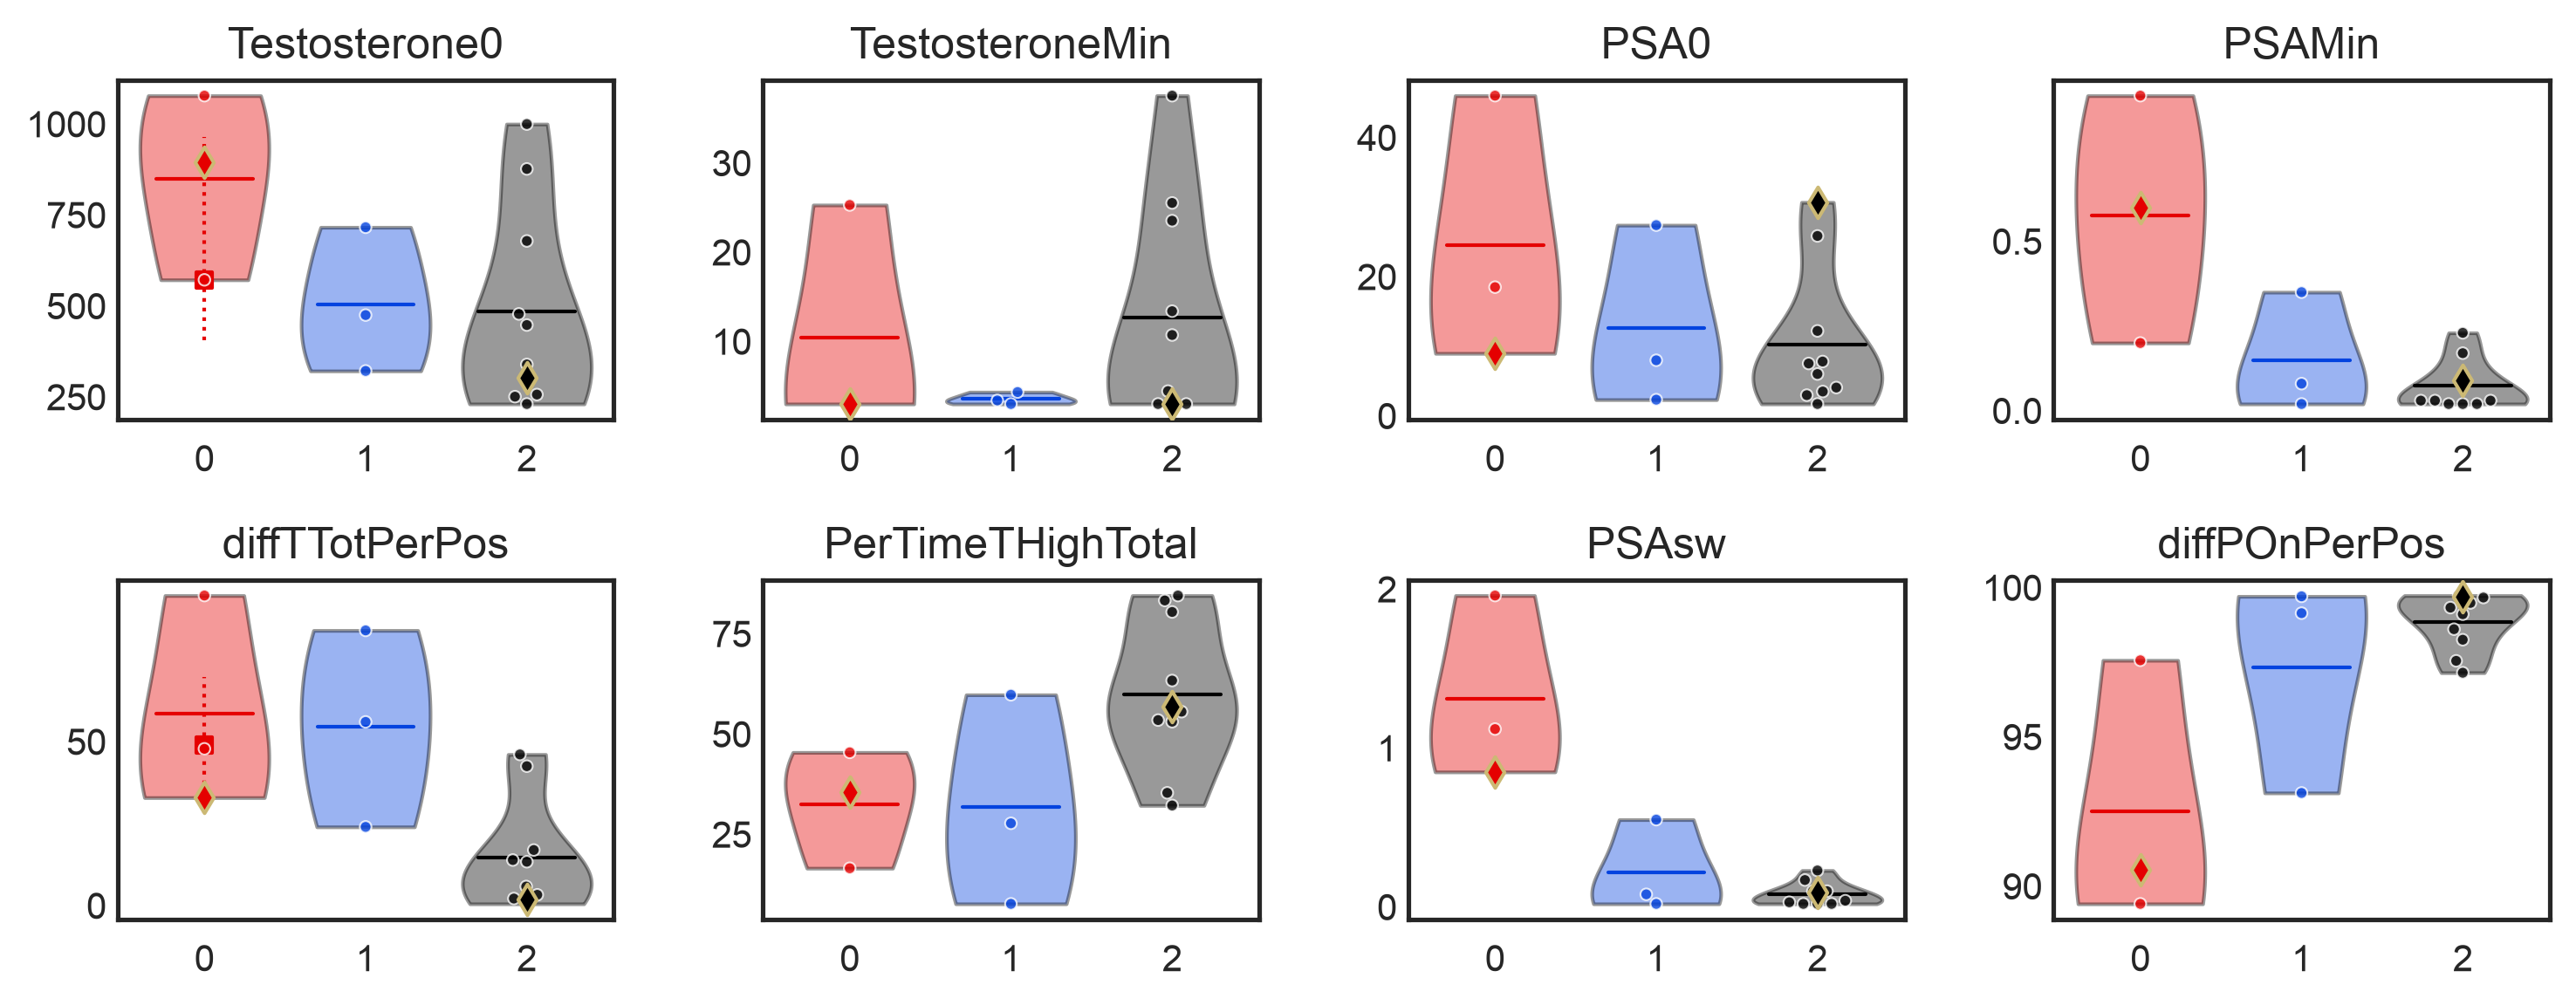

In [9]:
################################################################
# Options:
# choose the data to plot as clinical features, 
# Testosterone and PSA features, or P/T features
################################################################
plotsType = 'Testo&PSA' #options = {'clinical','Testo&PSA','P/T','mod','dT'}
plot9to5=True # plot diamonds for patients 105 and 109
hueCol='ELN'#options {'ELN','PN','RP','OS'}
exclude111=False #exclude patient 111 from the analysis

palette1 = sns.xkcd_palette(["red", "blue", "black"])
palette2 = sns.xkcd_palette(["black", "red"])

#patient 11 missing info 
pn=allDf[allDf['PN']==1]#allDf#
pn=pn[pn['id']!=11]
pp1=pn[pn['names']=='Testosterone0']
pp2=pn[pn['names']=='diffTTotPerPos']
meanTchange=np.mean(pp2['values'])
stdTchange=np.std(pp2['values'])
TF11=292
P011=46.03
deltaTmin=meanTchange-stdTchange
deltaTmean=meanTchange
deltaTmax=meanTchange+stdTchange
Tmin=TF11/(1-deltaTmin/100)
Tmean=TF11/(1-deltaTmean/100)
Tmax=TF11/(1-deltaTmax/100)

if(plotsType=='clinical'):
    plotNames=['Gleason','Total mets','BMs','LNs','risk','de novo','Age','BMI']#,'dAbi']#
    rows0=2
    colsN=4
elif(plotsType=='Testo&PSA'):
    plotNames=['Testosterone0','TestosteroneMin','PSA0','PSAMin','diffTTotPerPos','PerTimeTHighTotal','PSAsw','diffPOnPerPos']#,
    rows0=2
    colsN=4
elif(plotsType=='P/T'):
    plotNames=['PSA0/T0','PSAF/TF','avePSA/T','maxPSA/T','diffOnPer2','diffOffRate']
    rows0=2
    colsN=4
elif(plotsType=='dT'):
    plotNames=['maxTfit','gRTfit','tdelayfit','dRPfit','dRTfit','minPfit','gRPfit','maxPfit']#,'minTfit'
    rows0=2
    colsN=4
else:
    plotNames=['X0','rS']
    rows0=2
    colsN=4

fig, axes = plt.subplots(rows0, colsN, figsize=(10,4),dpi=300)
x=0
y=0
for pn in plotNames:
    print(pn)
    pp=allDf[allDf['names']==pn]
    if(exclude111):
        if(pn=='Testosterone0' or pn=='diffTTotPerPos' or pn=='PSA0/T0' or pn=='avePSA/T'):
            pp=pp[pp['id']!=11]
    if(pn=='Gleason' or pn=='risk'):
            pp=pp[pp['id']!=8]
    pp=pp[~pp['values'].isna()]
    if(hueCol=='ELN'):
        EP=pp[pp[hueCol]==0]['values'].values.tolist()
        LP=pp[pp[hueCol]==1]['values'].values.tolist()
        NP=pp[pp[hueCol]==2]['values'].values.tolist()
        fow=stats.f_oneway(EP, LP, NP)
        kw_stat, kw_p = stats.kruskal(EP, LP, NP)
        palette0=palette1
        means=[np.mean(EP),np.mean(LP),np.mean(NP)]
    elif(hueCol=='PN'):
        P=pp[pp[hueCol]==1]['values'].values.tolist()
        NP=pp[pp[hueCol]==0]['values'].values.tolist()
        fow=stats.f_oneway(NP,P)
        kw_stat, kw_p = stats.kruskal(NP,P)
        palette0=palette2
        means=[np.mean(NP),np.mean(P)]
    elif(hueCol=='RP'):
        P=pp[pp[hueCol]==1]['values'].values.tolist()
        NP=pp[pp[hueCol]==0]['values'].values.tolist()
        fow=stats.f_oneway(NP,P)
        kw_stat, kw_p = stats.kruskal(NP,P)
        palette0=palette2
        means=[np.mean(NP),np.mean(P)]
    else:
        P=pp[pp[hueCol]==1]['values'].values.tolist()
        NP=pp[pp[hueCol]==0]['values'].values.tolist()
        fow=stats.f_oneway(NP,P)
        kw_stat, kw_p = stats.kruskal(NP,P)
        palette0=palette1
        means=[np.mean(NP),np.mean(P)]
    print('fow')
    print(fow.pvalue)
    print('kw')
    print(kw_p)
    
    if(pn=='Gleason'):
        inds=pp['values'].isnull()
        pp=pp[~inds]

    plots=sns.violinplot(data=pp, x=hueCol, y='values', cut=0,
               density_norm='width',inner=None, linewidth=1, palette=palette0,hue=hueCol, 
               saturation=1, ax=axes[y][x])
    
    for patch in plots.collections:
        patch.set_alpha(0.4)

    for mi,m in enumerate(means):
        axes[y][x].plot([mi-.3,mi+.3],[means[mi],means[mi]],c=palette0[mi],linewidth=1)

    if(plot9to5):spp=pp[(pp['id']!=5) & (pp['id']!=9)]
    else:spp=pp
    sns.swarmplot(data=spp, x=hueCol, y='values', hue=hueCol,ax=axes[y][x],
               palette=palette0,size=3.2,alpha=.8,linewidth=0.5,edgecolor='white')

    if(plot9to5):
        if(hueCol=='ELN'):
            x5=2
            x9=0
        else:
            x5=0
            x9=1
        pp5=pp[pp['id']==5]
        axes[y][x].scatter(x5,pp5['values'],marker='d',color=palette1[2],edgecolor='y',zorder=10)
        pp9=pp[pp['id']==9]
        axes[y][x].scatter(x9,pp9['values'],marker='d',color=palette1[0],edgecolor='y',zorder=10)

    if(hueCol=='ELN'):
        if(pn=='Testosterone0'):
            axes[y][x].scatter(0, Tmean, color=palette1[0], s=20,marker='s')
            axes[y][x].plot([0,0], [Tmin,Tmax], color=palette1[0], linewidth=1, linestyle=":")
        if(pn=='diffTTotPerPos'):        
            axes[y][x].scatter(0, deltaTmean, color=palette1[0], s=20,marker='s')
            axes[y][x].plot([0,0], [deltaTmin,deltaTmax], color=palette1[0], linewidth=1, linestyle=":")
        if(pn=='PSA0/T0'):
            axes[y][x].scatter(0, .01*P011/Tmean, color=palette1[0], s=20,marker='s')
            axes[y][x].plot([0,0], [.01*P011/Tmin,.01*P011/Tmax], color=palette1[0], linewidth=1, linestyle=":")
        if(pn=='avePSA/T'):
            dataD = initialize.loadData(dataDfName,111,txCols)
            dataD.at[0,'Testosterone']=Tmean
            aptmean=(.01*np.nanmean(dataD['PSA']/dataD['Testosterone']))
            dataD.at[0,'Testosterone']=Tmin
            aptmin=(.01*np.nanmean(dataD['PSA']/dataD['Testosterone']))
            dataD.at[0,'Testosterone']=Tmax
            aptmax=(.01*np.nanmean(dataD['PSA']/dataD['Testosterone']))
            axes[y][x].scatter(0, aptmean, color=palette1[0], s=20,marker='s')
            axes[y][x].plot([0,0], [aptmin,aptmax], color=palette1[0], linewidth=1, linestyle=":")


    axes[y][x].get_legend().remove()
    axes[y][x].set_title(pn,fontsize=12)
    axes[y][x].set_xlabel('')
    axes[y][x].set_ylabel('')
    axes[y][x].tick_params(labelsize=10)
    axes[y][x].tick_params("y", pad=-3)

    x=x+1
    if(x>=colsN):
        x=0
        y=y+1
plt.tight_layout()

## p-value heatmap and BH procedure

22
       pnewf     pnewk      Sum2  sig_fow  sig_kw          metric
1   0.038740  0.067166  0.105906     True   False           PSAsw
5   0.046129  0.067166  0.113295     True   False          PSAMin
10  0.008152  0.067166  0.075318     True   False        avePSA/T
11  0.015676  0.067166  0.082842     True   False       |1-TF/T0|
12  0.000231  0.067166  0.067397     True   False  |1-PSAsw/PSA0|
13  0.009802  0.083731  0.093533     True   False      Total mets
16  0.008152  0.067166  0.075318     True   False            dPSA
21  0.038740  0.067166  0.105906     True   False             Age


/var/folders/y3/nxptvxqn0z12b_ylwgl4x68h000wg8/T/ipykernel_12492/3418968998.py:109: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  BB['pnewf']= adjusted_p_values_fow
/var/folders/y3/nxptvxqn0z12b_ylwgl4x68h000wg8/T/ipykernel_12492/3418968998.py:110: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  BB['sig_fow'] = adjusted_p_values_fow < FDR
/var/folders/y3/nxptvxqn0z12b_ylwgl4x68h000wg8/T/ipykernel_12492/3418968998.py:112: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFram

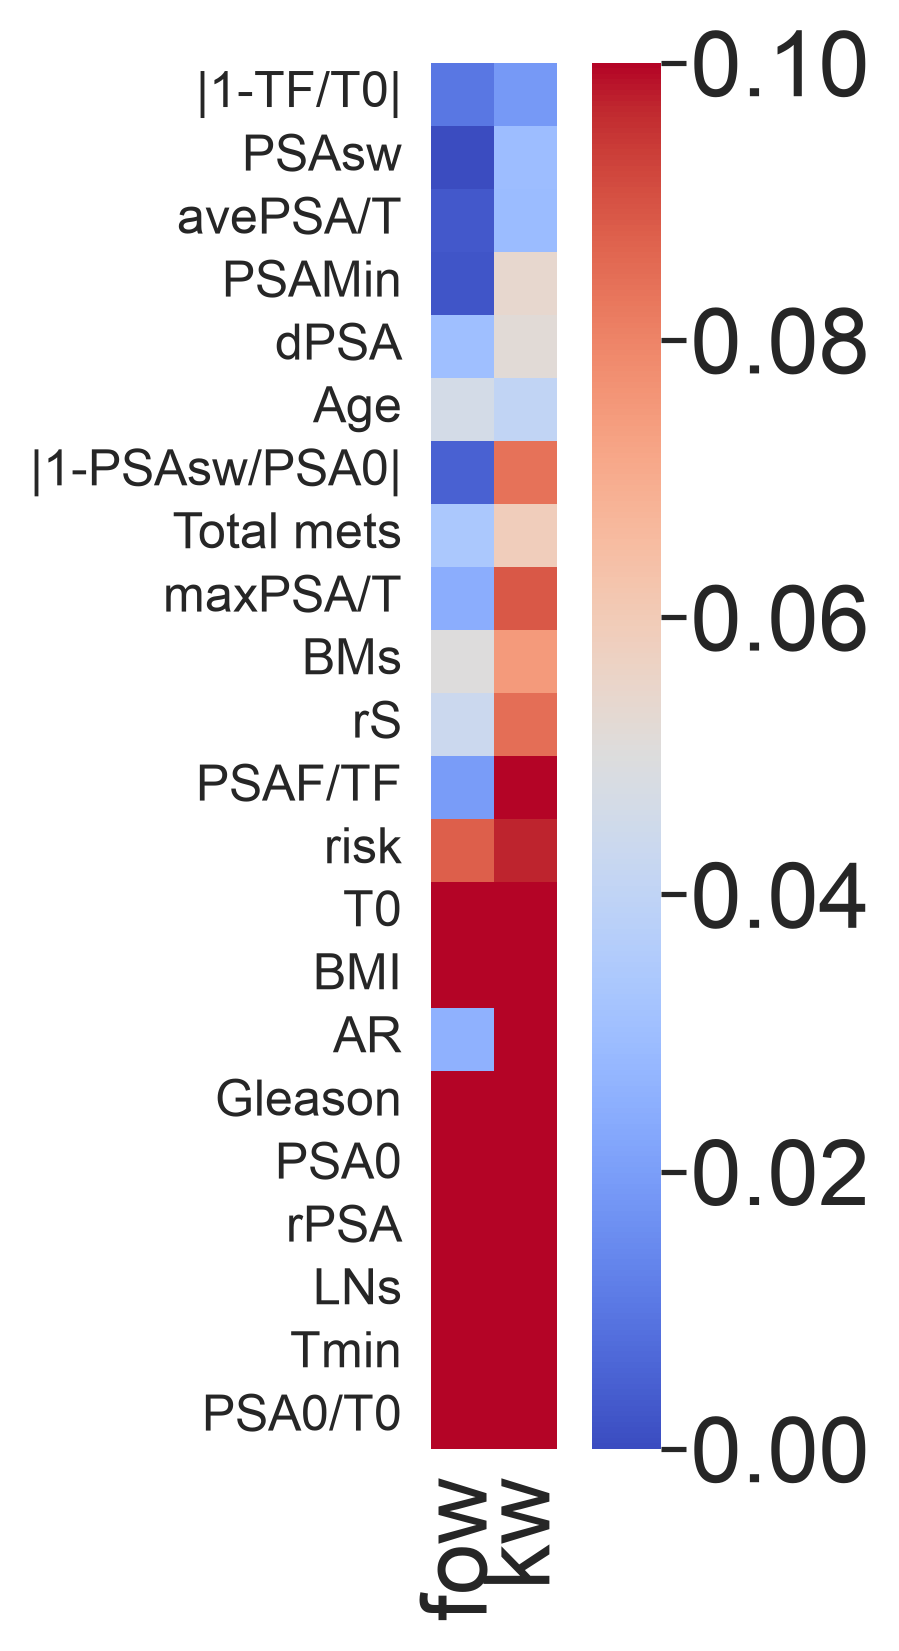

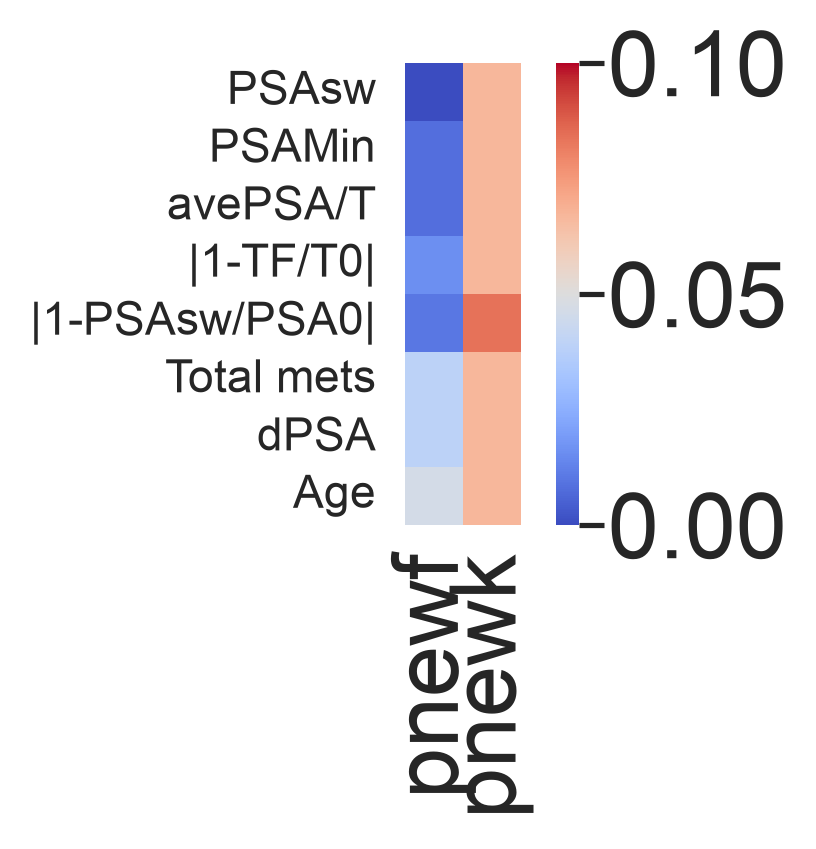

In [10]:
plotType='ELN'#options={'ELN','PN','RP','OS'}

metrics=['Gleason','Total mets','BMs','LNs','risk','Age','BMI',#'de novo','dAbi',
         'Testosterone0','TestosteroneMin','PSA0','PSAMin','diffTTotPerPos','PSAsw','diffPOnPerPos',
         'PSA0/T0','PSAF/TF','avePSA/T','maxPSA/T',
         'X0','rS',
         'gRPfit','dRPfit']#,'maxTfit','gRTfit','tdelayfit','maxPfit','minTfit','dRTfit','minPfit']#'PerTimeTHighTotal',

progCrit=['ELN','PN','RP','OS']
fe=[]
fp=[]
fr=[]
fo=[]
ke=[]
kp=[]
kr=[]
ko=[]

for prog in progCrit:
    for metric in metrics:
        pp=allDf[allDf['names']==metric]
        if(metric=='Gleason' or metric=='risk'):
            pp=pp[pp['id']!=8]
        pp=pp[~pp['values'].isna()]
        if(prog=='ELN'):
            EP=pp[pp[prog]==0]['values'].values.tolist()
            LP=pp[pp[prog]==1]['values'].values.tolist()
            NP=pp[pp[prog]==2]['values'].values.tolist()
            fow_stat,fow_p=stats.f_oneway(EP, LP, NP)
            kw_stat, kw_p = stats.kruskal(EP, LP, NP)
            fe.append(fow_p)
            ke.append(kw_p)
        else:
            P=pp[pp[prog]==1]['values'].values.tolist()
            NP=pp[pp[prog]==0]['values'].values.tolist()
            fow_stat,fow_p=stats.f_oneway(P, NP)
            kw_stat, kw_p = stats.kruskal(P, NP)
            if(prog=='PN'):
                fp.append(fow_p)
                kp.append(kw_p)
            elif(prog=='RP'):
                fr.append(fow_p)
                kr.append(kw_p)
            else:
                fo.append(fow_p)
                ko.append(kw_p)

fow=pd.DataFrame()
fow['ELN']=fe
fow['PN']=fp
fow['RP']=fr
fow['OS']=fo
kw=pd.DataFrame()
kw['ELN']=ke
kw['PN']=kp
kw['RP']=kr
kw['OS']=ko

eln=pd.DataFrame()
eln['fow']=fe
eln['kw']=ke
pn=pd.DataFrame()
pn['fow']=fp
pn['kw']=kp
rp=pd.DataFrame()
rp['fow']=fr
rp['kw']=kr
os=pd.DataFrame()
os['fow']=fo
os['kw']=ko


if(plotType=='ELN'):AA=eln
if(plotType=='PN'):AA=pn
if(plotType=='RP'):AA=rp
if(plotType=='OS'):AA=os

AA['Sum']=AA['fow']+AA['kw']
AA_sorted=AA.sort_values(by='Sum')
msort=[]
for ii,ind in enumerate(AA_sorted.index):
    met=metrics[AA_sorted.index[ii]]
    if(met=='Testosterone0'):met='T0'
    if(met=='TestosteroneMin'):met='Tmin'
    if(met=='dAbi'):met='Abi'
    if(met=='X0'):met='AR'
    if(met=='diffTTotPerPos'):met='|1-TF/T0|'
    if(met=='diffPOnPerPos'):met='|1-PSAsw/PSA0|'
    if(met=='dRPfit'):met='dPSA'
    if(met=='gRPfit'):met='rPSA'
    msort.append(met)
AA_sorted=AA_sorted.drop(columns=['Sum'])
fig, ax = plt.subplots(1, 1, figsize=(3,6),dpi=300)
ax=sns.heatmap(AA_sorted, annot=False, vmin=0,vmax=.1,cmap='coolwarm', square=True)
labels0=[str(x) for x in msort]
positions=[0.5+x for x in range(0,len(labels0))]
ax.set_yticks(positions)
ax.set_yticklabels(labels0, fontsize=12)
plt.yticks(rotation=0)

########
##BH procedure
FDR=0.05# 
AA['metrics']=metrics
print(len(AA))
BB=AA[(AA['Sum']/2)<=.05]

adjusted_p_values_fow = stats.false_discovery_control(BB['fow'], method='bh')
BB['pnewf']= adjusted_p_values_fow 
BB['sig_fow'] = adjusted_p_values_fow < FDR
adjusted_p_values_kw = stats.false_discovery_control(BB['kw'], method='bh')
BB['pnewk']= adjusted_p_values_kw 
BB['sig_kw'] = adjusted_p_values_kw < FDR
#AA[['metrics','sigfow','sig_fow','sigkw','sig_kw']]
#AA[['metrics','sigfow','sigkw']]
BB=BB[['pnewf','pnewk']]

## heatmap
BB['Sum2']=BB['pnewf']+BB['pnewk']
BB_sorted=BB.sort_values(by='Sum2')
# AA['Ave']=(AA['fow']+AA['kw'])/2
# AA_sorted=AA.sort_values(by='Ave')
msort=[]
for ii,ind in enumerate(BB_sorted.index):
    met=metrics[BB_sorted.index[ii]]
    if(met=='Testosterone0'):met='T0'
    if(met=='TestosteroneMin'):met='Tmin'
    if(met=='dAbi'):met='Abi'
    if(met=='X0'):met='AR'
    if(met=='diffTTotPerPos'):met='|1-TF/T0|'#'|T0-TF|/T0'
    if(met=='diffPOnPerPos'):met='|1-PSAsw/PSA0|'
    if(met=='dRPfit'):met='dPSA'
    if(met=='gRPfit'):met='rPSA'
    msort.append(met)
BB_sorted=BB_sorted.drop(columns=['Sum2'])
#AA_sorted=AA_sorted.drop(columns=['Ave'])
fig, ax = plt.subplots(1, 1, figsize=(3,2),dpi=300)
ax=sns.heatmap(BB_sorted, annot=False, vmin=0,vmax=.1,cmap='coolwarm', square=True)
labels0=[str(x) for x in msort]
positions=[0.5+x for x in range(0,len(labels0))]
ax.set_yticks(positions)
ax.set_yticklabels(labels0, fontsize=11)
plt.yticks(rotation=0)

BB['sig_fow'] = adjusted_p_values_fow < FDR
BB['sig_kw'] = adjusted_p_values_kw < FDR
BB['metric'] = msort
print(BB)

## K-means analysis

In [ ]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

dfNew=pd.DataFrame()
for pN in np.unique(allDf['names']):
    if(pN!='Gleason'):
        vals=allDf[allDf['names']==pN]['values']
        vals=vals.reset_index(drop = True)
        dfNew[pN]=vals

cols=['PSAsw','avePSA/T']#,'PSAMin',#,'rS']#,'diffTTotPerPos']#'diffPOnPer']#]#
#cols=['PSAsw','avePSA/T','diffTTotPerPos','diffPOnPer','PSAMin','PSAF/TF','maxPSA/T','X0','dRPfit']
dfNew2=dfNew[cols]
X_scaled=dfNew2.copy()

#scale data
scaler = StandardScaler()
scaledData=scaler.fit_transform(X_scaled)

# # Create a KMeans model with 2 clusters
kmeans = KMeans(n_clusters=3)

# # Fit the model to the data
kmeans.fit(scaledData)

# # Get the cluster labels for each data point
labels = kmeans.labels_

for ci,coli in enumerate(scaledData.T):
    str=cols[ci]+'S'
    X_scaled.loc[:,str]=coli

# # Add the labels to the DataFrame
X_scaled['cluster']=labels
print(kmeans.cluster_centers_)

cats=[0,2,2,2,1,1,2,0,2,0,2,2,2,2,1,2]
X_scaled['cats']=cats

pca_num_components = 2

reduced_data = PCA(n_components=pca_num_components).fit_transform(X_scaled.iloc[:,2:4])#scaled columns for 2 parameters is at 2,3
results = pd.DataFrame(reduced_data,columns=['pca1','pca2'])

sns.scatterplot(x="pca1", y="pca2", data=results, style=X_scaled['cluster'],color='black',s=50,palette=['r','b','k'],hue=X_scaled['cats'])
plt.title('K-means Clustering with 2 dimensions')
plt.legend('', frameon=False)
plt.show()

# threshold plot with labeled clusters

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4)) 
#sns.scatterplot(x="PSAsw", y="avePSA/T", data=dfNew2, style=dfNew2['cluster'],color='black',s=100,palette=['r','b','k'],hue=dfNew2['cats'])
sns.scatterplot(x="PSAsw", y="avePSA/T", data=X_scaled, style=X_scaled['cluster'],color='black',s=100,palette=['r','b','k'],hue=X_scaled['cats'])
ax.legend()
plt.gca().get_legend().set_visible(False)
ax.tick_params(axis='both', which='major', labelsize=11)
plt.plot([-.05,2.2],[.00045,.00045],color='k',linestyle=':')
plt.plot([.4,.4],[-.0001,.004],color='k',linestyle=':')

In [ ]:
import plotly.express as px
col0=['r','k','k','k','b','b','k','r','k','r','k','k','k','k','b','k']
dfNew['ELN']=allDf[allDf['names']=='dAbi']['ELN'].values
features = [ "PSAsw","avePSA/T","ELN"]#,'diffTTotPerPos'
dfF=dfNew[features]
sns.pairplot(dfF,hue='ELN',palette=palette0,diag_kind="kde",kind='scatter',plot_kws={"s": 100})